Ali Hisham AlJamed 2240005868 7MA1 / MA01

Task 1:

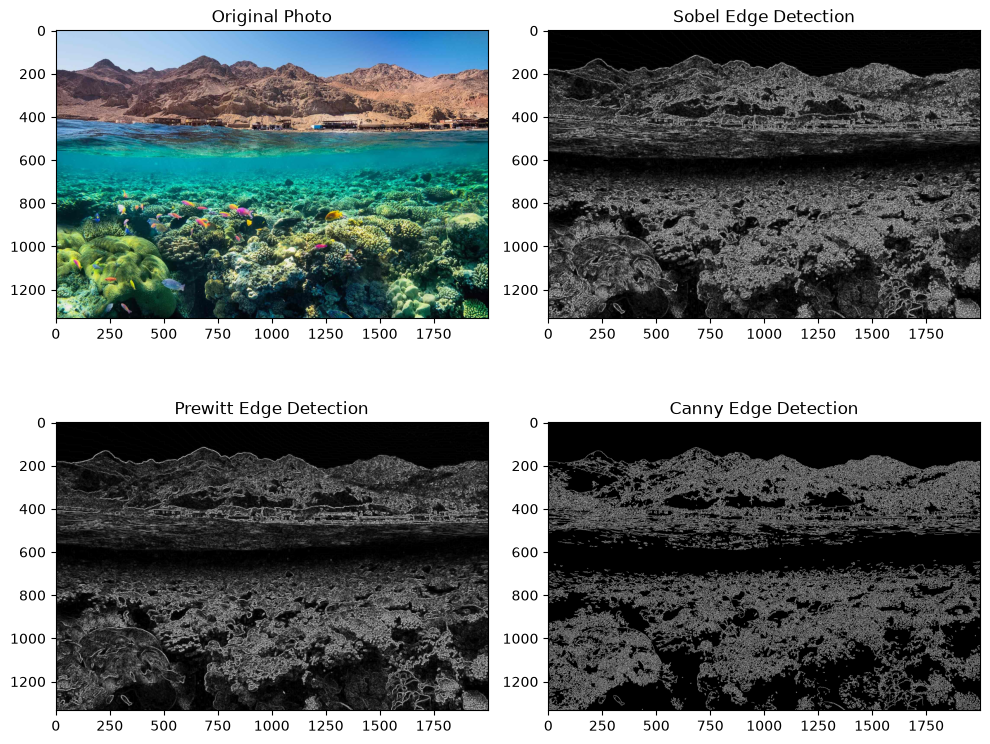

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
imgFile = "Red_Sea.jpg"
#Load a real image in grayscale
img = cv2.imread(imgFile)

#Grayscale & Blur (Essential for real photos to reduce grain)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

#Define Prewitt Kernels manually
kernel_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float64)
kernel_y = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float64)

#Apply filters
prewitt_x = cv2.filter2D(blurred, cv2.CV_64F, kernel_x)
prewitt_y = cv2.filter2D(blurred, cv2.CV_64F, kernel_y)

#Calculate Magnitude (Combine X and Y)
prewitt_combined = cv2.magnitude(prewitt_x, prewitt_y)

#Normalize to 8-bit for display
prewitt_final = np.uint8(np.absolute(prewitt_combined))

#Sobel
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0) # blurred = img or gray   ## Check the results

#Apply Sobel filter
# cv2.CV_64F handles the high precision needed for derivatives
sobelx = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)

#Calculate Magnitude (Final Edge Map)
sobel_combined = cv2.magnitude(sobelx, sobely)

#Normalize to 0-255 for display
sobel_final = np.uint8(np.absolute(sobel_combined))

#Canny
canny_edges = cv2.Canny(gray, 100, 200)

#Visualization 
plt.figure(figsize=(10, 8))

plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Original Photo')

plt.subplot(2, 2, 2)
plt.imshow(sobel_final, cmap='gray')
plt.title('Sobel Edge Detection')

plt.subplot(2, 2, 3)
plt.imshow(prewitt_final, cmap='gray')
plt.title('Prewitt Edge Detection')

plt.subplot(2, 2, 4)
plt.imshow(canny_edges, cmap='gray')
plt.title('Canny Edge Detection')

plt.tight_layout()
plt.show()

Task 2:

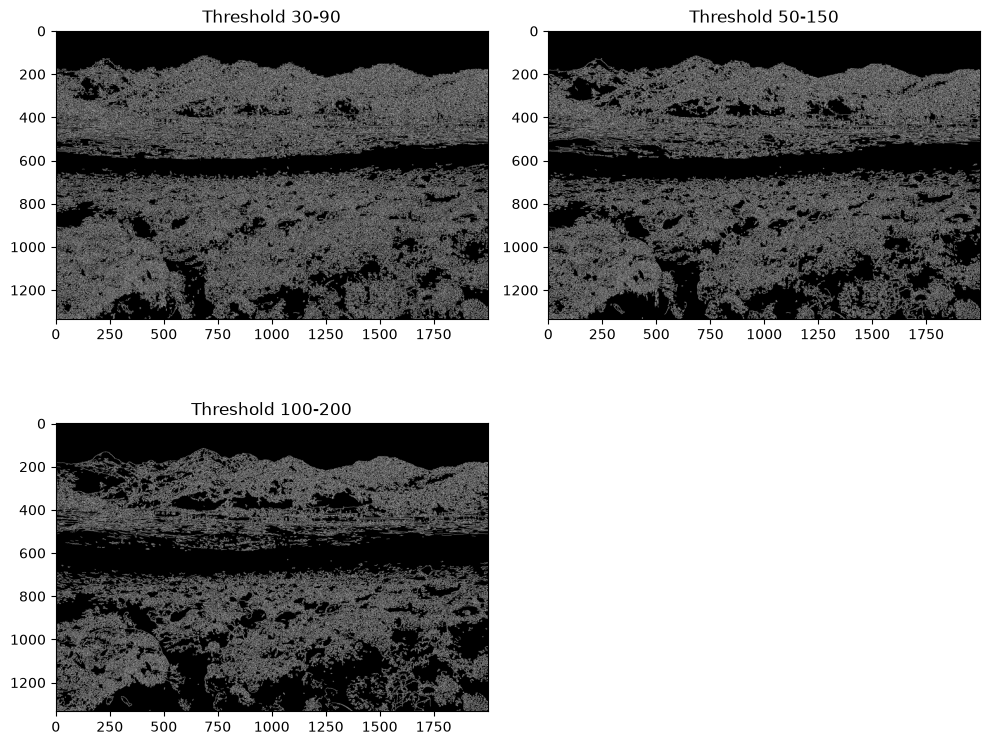

In [2]:
# Threshold 30-90
canny_edges1 = cv2.Canny(gray, 30, 90)

# Threshold 50-150
canny_edges2 = cv2.Canny(gray, 50, 150)

# Threshold 100-200
canny_edges3 = cv2.Canny(gray, 100, 200)

#Visualization 
plt.figure(figsize=(10, 8))


plt.subplot(2, 2, 1)
plt.imshow(canny_edges1, cmap='gray')
plt.title('Threshold 30-90')

plt.subplot(2, 2, 2)
plt.imshow(canny_edges2, cmap='gray')
plt.title('Threshold 50-150')

plt.subplot(2, 2, 3)
plt.imshow(canny_edges3, cmap='gray')
plt.title('Threshold 100-200')

plt.tight_layout()
plt.show()